<a href="https://colab.research.google.com/github/adhamov8/BDA_HW-shopper-analytics/blob/main/BDA_HW2_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Shopper · HW 2: Principal component analysis
Alibek Adhamov · Basic Methods of Data Analytics

How much of the variation in browsing activity can two coordinates retain, and where do sessions ending in a purchase appear on that map? The unit is one session. Source: [Online Shoppers Purchasing Intention, UCI](https://doi.org/10.24432/C5F88Q), CC BY 4.0. This is the same random sample of 500 sessions (seed 42) used in Assignment 1.

## A2.1 · Select one aspect of the data
The six variables describe browsing activity: counts of pages and time spent on administrative, informational and product-related pages. Together they distinguish short from extensive visits and capture how activity is distributed across sections. Revenue is reserved for labeling points after fitting; the source row ID is an identifier only.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

name = 'shopper_sample_500_seed42.csv'
url = 'https://raw.githubusercontent.com/adhamov8/BDA_HW-shopper-analytics/main/' + name
df = pd.read_csv(name if Path(name).is_file() else url)
features = ['Administrative', 'Administrative_Duration', 'Informational',
            'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration']
X = df[features].astype(float)
purchase = df['Revenue'].astype(str).str.lower().map({'true': True, 'false': False})
assert X.shape == (500, 6) and X.notna().all().all() and purchase.notna().all()
print('Dimensions:', X.shape, '| Purchase:', purchase.sum(), '| No purchase:', (~purchase).sum())

Dimensions: (500, 6) | Purchase: 73 | No purchase: 427


## A2.2 · Standardize and decompose
Both versions subtract each feature mean. Range scaling divides by the observed maximum minus minimum; z-scoring divides by the population standard deviation. In the SVD, the squared singular value is the absolute contribution of a component to the sum of squares (data scatter).

In [ ]:
span = X.max() - X.min()
tables = {'Range': (X-X.mean())/span, 'Z-score': (X-X.mean())/X.std(ddof=0)}
fits = {}
for label, Y in tables.items():
    U, s, Vt = np.linalg.svd(Y, full_matrices=False)
    # Give the strongest coefficient on each axis a positive sign.
    signs = np.sign(Vt[np.arange(len(s)), abs(Vt).argmax(axis=1)])
    Vt *= signs[:, None]
    U *= signs
    scatter = np.square(Y.to_numpy()).sum()
    pct = 100*s**2/scatter
    assert np.isclose(sum(s**2), scatter)
    fits[label] = (U*s, Vt, s, pct)
    print(label, '| total scatter:', round(scatter, 4))
    print(pd.DataFrame({'singular value': s, 'absolute scatter': s**2, 'percent': pct},
                       index=range(1,7)).round(3).to_string())

Range | total scatter: 46.4568
   singular value  absolute scatter  percent
1           5.261            27.678   59.578
2           2.935             8.617   18.548
3           2.130             4.536    9.765
4           1.732             3.000    6.458
5           1.526             2.330    5.016
6           0.543             0.295    0.635
Z-score | total scatter: 3000.0
   singular value  absolute scatter  percent
1          40.436          1635.095   54.503
2          23.558           554.983   18.499
3          21.494           461.986   15.400
4          13.001           169.029    5.634
5          11.728           137.556    4.585
6           6.430            41.350    1.378


## A2.3 · Visualize the first two components
Each marker is a session; triangles identify purchases. The axes are ordinary component scores (U times the singular values).

Range median PC1, purchase / no purchase: [-0.013 -0.12 ]
Z-score median PC1, purchase / no purchase: [ 0.212 -0.686]


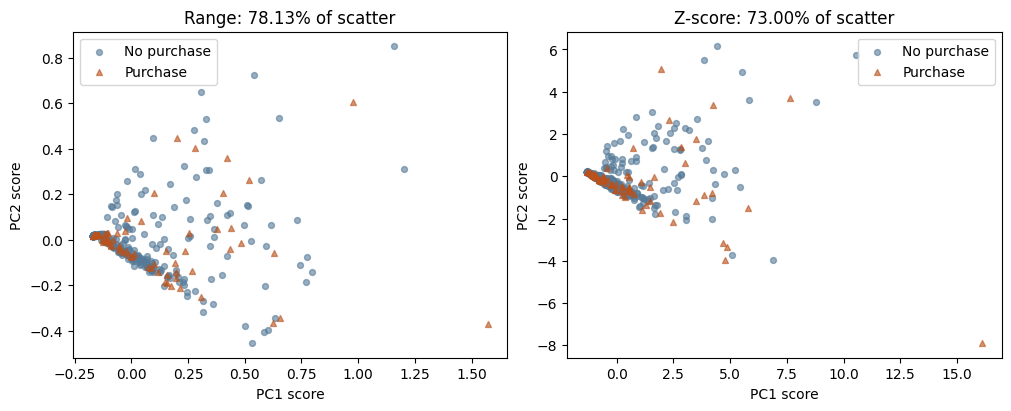

In [ ]:
def draw(ax, scores, label):
    for mask, marker, color, group in [(~purchase,'o','#557a98','No purchase'), (purchase,'^','#ba521c','Purchase')]:
        ax.scatter(scores[mask,0],scores[mask,1],s=18,alpha=.6,marker=marker,color=color,label=group)
    ax.set(xlabel='PC1 score', ylabel='PC2 score', title=label)
    ax.legend()
fig, axes = plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for ax, (label, (scores, _, _, pct)) in zip(axes, fits.items()):
    draw(ax, scores, f'{label}: {sum(pct[:2]):.2f}% of scatter')
    print(label, 'median PC1, purchase / no purchase:',
          np.round([np.median(scores[purchase,0]), np.median(scores[~purchase,0])],3))
plt.show()

The two axes retain 78.13% of range-scaled scatter and 73.00% of z-scored scatter. Purchase sessions tend to sit farther along the positive first axis: under z-scoring their median PC1 is 0.212, versus −0.686 for the other sessions. The groups overlap; these maps do not classify individual purchases.

## A2.4 · Interpret the loadings

In [ ]:
for label, (_, Vt, s, _) in fits.items():
    balanced_loadings = Vt[:2].T * np.sqrt(s[:2])
    print(label, 'balanced loadings (V times the square root of singular values)')
    print(pd.DataFrame(balanced_loadings, index=features, columns=['PC1','PC2']).round(3))

Range balanced loadings (V times the square root of singular values)
                           PC1    PC2
Administrative           1.616 -0.632
Administrative_Duration  0.959 -0.630
Informational            0.938  1.159
Informational_Duration   0.548  0.888
ProductRelated           0.583  0.016
ProductRelated_Duration  0.460  0.094
Z-score balanced loadings (V times the square root of singular values)
                           PC1    PC2
Administrative           2.761 -0.449
Administrative_Duration  2.437 -1.116
Informational            2.502  2.554
Informational_Duration   2.086  3.222
ProductRelated           2.846 -1.762
ProductRelated_Duration  2.857 -1.450


All six PC1 loadings are positive in both versions: a high score generally means broader or longer browsing. Under range scaling, administrative page count carries the most weight; under z-scoring, product page count and product time have the largest weights, with the others also contributing. PC2 under range scaling contrasts informational and administrative activity, with little weight on product browsing. Under z-scoring, informational duration and page count oppose product browsing and, more weakly, administrative activity. Neither component measures intent directly.

## A2.5 · Compare conventional PCA and choose a normalization
Compute the eigenvectors of the correlation matrix, project the standardized observations onto them, and align their signs with the SVD axes before comparing the coordinates.

Conventional contributions (%): [54.503 18.499]
Maximum coordinate difference: 3.597122599785507e-14


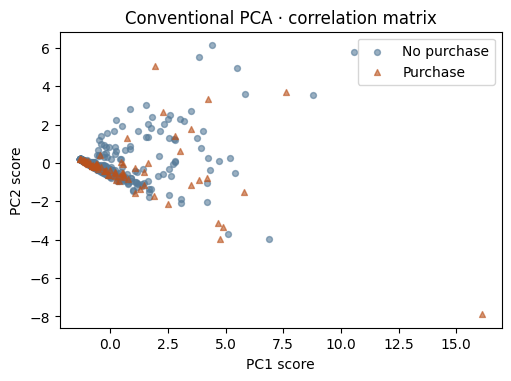

In [ ]:
Z = tables['Z-score'].to_numpy()
val, vec = np.linalg.eigh(Z.T @ Z / len(Z))
order = np.argsort(val)[::-1]
val, vec = val[order], vec[:, order[:2]]
scores, Vt, s, pct = fits['Z-score']
vec *= np.sign(np.sum(vec * Vt[:2].T, axis=0))
conventional = Z @ vec
print('Conventional contributions (%):', np.round(100*val[:2]/val.sum(), 3))
print('Maximum coordinate difference:', np.max(abs(conventional-scores[:,:2])))
assert np.allclose(conventional, scores[:,:2])
fig, ax = plt.subplots(figsize=(5,3.7), constrained_layout=True)
draw(ax, conventional, 'Conventional PCA · correlation matrix')
plt.show()

The conventional map reproduces the z-scored SVD projection up to numerical precision. Range scaling retains more of its own scatter in two dimensions, but gives administrative page count greater influence. I prefer z-scoring for the question about overall browsing activity: each input feature starts with the same variance despite differing units and ranges. The two percentages refer to different standardized tables.

## A2.6 · Construct a browsing activity score from 0 to 100
Following the worked example, convert each feature to a 0–100 scale using its observed minimum and maximum. Compute the first SVD factor without centering, then rescale the session scores to the observed 0–100 range.

In [ ]:
R = 100*(X-X.min())/span
_, s_rank, V_rank = np.linalg.svd(R, full_matrices=False)
weights = V_rank[0] * np.sign(V_rank[0].sum())
raw = R.to_numpy() @ weights
activity = 100*(raw-raw.min())/np.ptp(raw)
print('Factor weights:')
print(pd.Series(weights, index=features).round(3))
print('Share of uncentered scatter (%):', round(100*s_rank[0]**2/sum(s_rank**2),2))
ranked = R.round(1).assign(activity=activity.round(2), source_id=df.row_id_in_source)
print(ranked.sort_values('activity').iloc[[0,249,-1]].to_string(index=False))
assert np.all(weights>=0) and np.allclose([activity.min(),activity.max()],[0,100])

Factor weights:
Administrative             0.719
Administrative_Duration    0.408
Informational              0.367
Informational_Duration     0.206
ProductRelated             0.298
ProductRelated_Duration    0.226
dtype: float64
Share of uncentered scatter (%): 68.99
 Administrative  Administrative_Duration  Informational  Informational_Duration  ProductRelated  ProductRelated_Duration  activity  source_id
            0.0                      0.0            0.0                     0.0             0.0                      0.0      0.00      11865
            0.0                      0.0            0.0                     0.0            12.4                     16.6      4.14       9627
          100.0                    100.0           33.3                    11.5           100.0                    100.0    100.00       8784


Higher scores describe more extensive browsing on the weighted combination of the six inputs. A score of 100 identifies the highest-scoring observed session; it does not mean that every input reached its maximum or that a purchase was certain. Because the ranked table was not centered, its scatter share is not a percentage of centered variance.